<a href="https://colab.research.google.com/github/DingiestParrot221103/Algorithms-and-data-strictures/blob/main/COM7017_WEEK_6_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [90]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


NumPy is used for calculations (numerical) and arrays

Matplotlib visualizes data

TensorFlow and Keras used to create train evaluate neural network

In [91]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("First label:", y_train[0])

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
First label: 5


The test dataset is used to evaluate the model's performance on unseen data

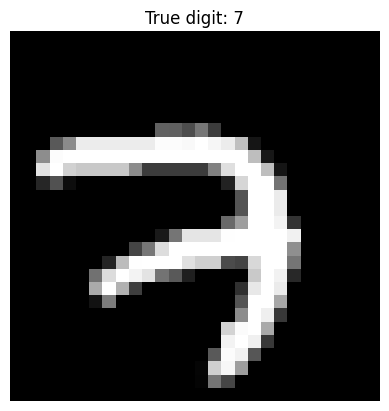

In [92]:
index = 5000

plt.imshow(x_train[index], cmap="gray")
plt.title(f"True digit: {y_train[index]}")
plt.axis("off")
plt.show()

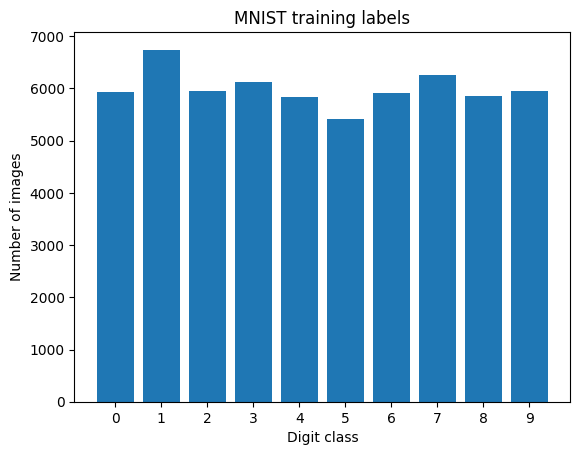

In [93]:
counts = np.bincount(y_train, minlength=10)

plt.bar(range(10), counts)
plt.xticks(range(10))
plt.xlabel("Digit class")
plt.ylabel("Number of images")
plt.title("MNIST training labels")
plt.show()

MNIST dataset was explored utilising Matplotlib - displays individual handwritten digits

Bar chart was created w/ NumPy to show the distribution of digits.

Grayscale colour map was used to display image in grayscale

Number 2 appeared most frequently in the bar chart

When I changed the image index, the true digit output changed

We use cmap="gray" to portray pics in grayscale not colour

In [94]:
print("Original range:", x_train.min(), x_train.max())
print("Original label:", y_train[0])

Original range: 0 255
Original label: 5


In [95]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [96]:
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

In [97]:
y_train = keras.utils.to_categorical(y_train, 10)
y_test = keras.utils.to_categorical(y_test, 10)

In [98]:
print("Processed shape:", x_train.shape)
print("Pixel range:", x_train.min(), x_train.max())
print("One-hot label:", y_train[0])

Processed shape: (60000, 28, 28, 1)
Pixel range: 0.0 1.0
One-hot label: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [99]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(8, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

In [100]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         4,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,258 (20.54 KB)

 Trainable params: 5,258 (20.54 KB)

 Non-trainable params: 0 (0.00 B)

In [101]:
layers.Dense(10, activation="softmax")

<Dense name=dense_5, built=False>

A CNN was created using Keras

The model uses two convolutional layers with ReLU and 2 max pooling layers to identify and reduce image features

Final dense layer contains 10 neurons with softmax activation to classify digits from 0 - 9

In [102]:
model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

In [103]:
history = model.fit(x_train, y_train, epochs=3,
                    batch_size=128, validation_split=0.1,
                    verbose=1)

Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - accuracy: 0.8512 - loss: 0.5180 - val_accuracy: 0.9555 - val_loss: 0.1470
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.9562 - loss: 0.1482 - val_accuracy: 0.9715 - val_loss: 0.0994
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.9673 - loss: 0.1085 - val_accuracy: 0.9772 - val_loss: 0.0784


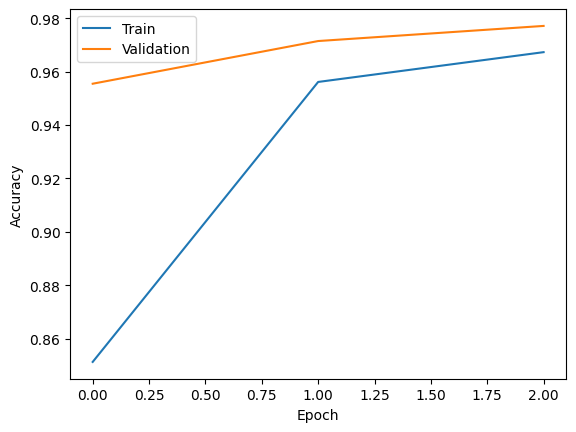

In [104]:
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [105]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))

Test loss: 0.0824
Test accuracy: 0.9742


The CNN was compiled with Adam optimiser, cross entropy loss function and accuracy as the evaluation metric

Model was trained over three epochs, 128 batch size, 10% validation split

Training and validation accuracy was plotted to evaluate performance, using seperate dataset to measure skill in classifying handwritten digits


What was your test accuracy? - 97.7%

Was validation accuracy similar to training accuracy? - close, about 20% out

What might a large gap between training and validation accuracy indicate? - overfitting

In [106]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

probs = model.predict(x_test, verbose=0)

pred = np.argmax(probs, axis=1)
true = np.argmax(y_test, axis=1)

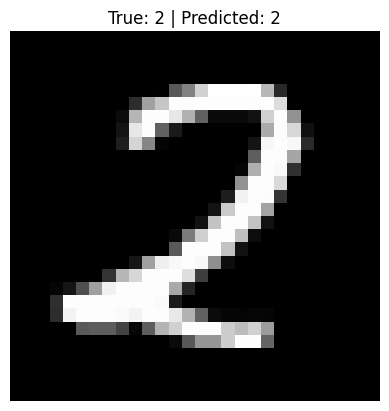

In [107]:
idx = 690

plt.imshow(x_test[idx].squeeze(), cmap="gray")
plt.title(f"True: {true[idx]} | Predicted: {pred[idx]}")
plt.axis("off")
plt.show()

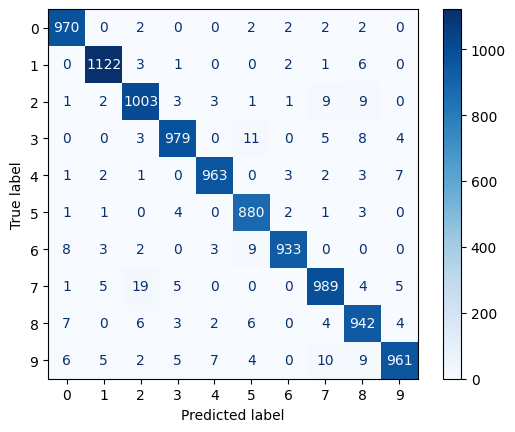

In [108]:
#confusion matrix
cm = confusion_matrix(true, pred)

ConfusionMatrixDisplay(
    cm, display_labels=range(10)
).plot(cmap="Blues", values_format="d")

plt.show()

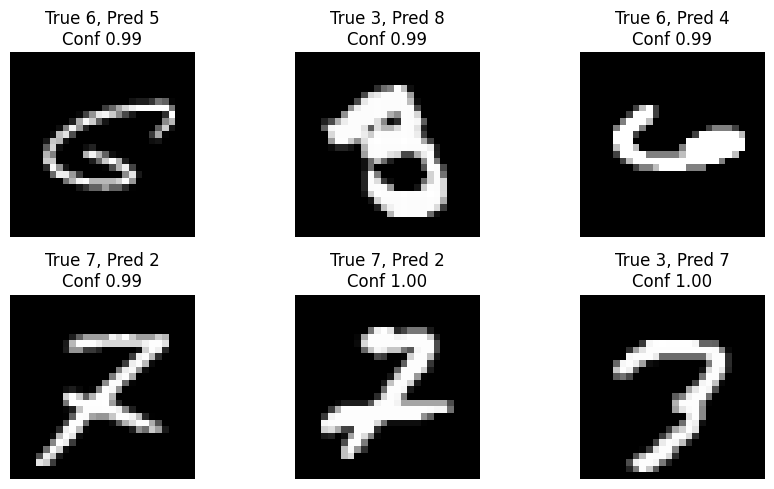

In [109]:
wrong = np.where(pred != true)[0]

chosen = wrong[np.argsort(
    probs[wrong].max(axis=1)
)[-6:]]

fig, axes = plt.subplots(2, 3, figsize=(9, 5))

for ax, i in zip(axes.flat, chosen):
    ax.imshow(x_test[i].squeeze(), cmap="gray")
    ax.set_title(
        f"True {true[i]}, Pred {pred[i]}\n"
        f"Conf {probs[i, pred[i]]:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

What does the diagonal in the confusion matrix mean? - The diagonal represents correctly classified images, predicted digit matches the actual digit.

2. Choose one high-confidence error and explain why the model may have failed.

Example answer:

"The model incorrectly classified a 6 as a 1 with high confidence (0.99).
may have happened because the handwriting was unclear (look at it christ) or the digits had similar visuals.
This shows that neural networks can sometimes be wrong even when they are confident